In [21]:
import os
import cv2
import numpy as np
import random
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

path_to_folder = './data'

IMAGE_SIZE = 45

name_folders = [x[0].split('\\')[-1] for x in os.walk(path_to_folder)][1:]
NUM_CLASSES = len(name_folders)

print(f"Число классов: {NUM_CLASSES}")
print(name_folders)

Число классов: 22
['(', ')', '+', ',', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '1', '9', 'h', 't', 'times', 'w', 'X', 'y']


Загрузка данных

In [22]:
X = []
y = []
samples_by_class = {i: [] for i in range(len(name_folders))}

for idx, folder in enumerate(name_folders):
    folder_path = os.path.join(path_to_folder, folder)
    if not os.path.exists(folder_path):
        continue
    for filename in os.listdir(folder_path):
        img_path = os.path.join(folder_path, filename)
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue
        img = cv2.bitwise_not(img)

        img_resized = cv2.resize(img, (IMAGE_SIZE, IMAGE_SIZE))
        img_norm = img_resized.astype(np.float32) / 255.0
        
        samples_by_class[idx].append(img_resized)
        X.append(img_norm.flatten()) 
        y.append(idx)

X = np.array(X)
y = np.array(y)

Сплит

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

k ближайших соседей

In [24]:
best_k = 1
best_acc = 0.0
k_values = [1,3,5,7,11,15,23]

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn.fit(X_train, y_train)
    preds = knn.predict(X_test)
    acc = accuracy_score(y_test, preds)
    print(f"k = {k}, accuracy = {acc:.4f}")
    if acc > best_acc:
        best_acc = acc
        best_k = k

print(f"\nОптимальный классификатор: k = {best_k} (Accuracy: {best_acc:.4f})")
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train, y_train)
print(classification_report(y_test, preds, target_names=name_folders, zero_division=0))

k = 1, accuracy = 0.8712
k = 3, accuracy = 0.8037
k = 5, accuracy = 0.6823
k = 7, accuracy = 0.6335
k = 11, accuracy = 0.5853
k = 15, accuracy = 0.5369
k = 23, accuracy = 0.4709

Оптимальный классификатор: k = 1 (Accuracy: 0.8712)
              precision    recall  f1-score   support

           (       0.43      0.95      0.59      2859
           )       0.38      0.98      0.54      2871
           +       0.89      0.28      0.43      5022
           ,       0.04      0.32      0.07       381
           -       0.65      1.00      0.78      6799
           0       1.00      0.52      0.68      1383
           1       0.24      0.34      0.28      5304
           2       0.88      0.51      0.64      5228
           3       0.85      0.54      0.66      2182
           4       0.96      0.19      0.32      1479
           5       0.86      0.17      0.29       709
           6       0.98      0.14      0.25       624
           7       0.77      0.22      0.34       582
           8

Генерация последовательности символов

In [28]:
def generate_sequence_image(samples_dict, class_names, num_words=3, word_len=3):
    target_string = ""
    char_images = []
    
    char_spacing = 10
    space_width = IMAGE_SIZE*2
    
    for w in range(num_words):
        for _ in range(word_len):
            valid_classes = [c for c, imgs in samples_dict.items() if len(imgs) > 0]
            cls_idx = random.choice(valid_classes)
            
            target_string += class_names[cls_idx]
            img = random.choice(samples_dict[cls_idx])
            
            char_images.append(img)
            char_images.append(np.zeros((IMAGE_SIZE, char_spacing), dtype=np.uint8))
            
        if w < num_words - 1:
            target_string += " "
            char_images.append(np.zeros((IMAGE_SIZE, space_width), dtype=np.uint8))
            
    combined = np.hstack(char_images)
    canvas = np.zeros((IMAGE_SIZE + 40, combined.shape[1] + 40), dtype=np.uint8)
    canvas[20:20+IMAGE_SIZE, 20:20+combined.shape[1]] = combined
    
    canvas_bgr = cv2.cvtColor(canvas, cv2.COLOR_GRAY2BGR)
    return target_string, canvas_bgr

Распознование

In [53]:
def recognize_sequence(img, model, class_names, space_threshold=IMAGE_SIZE+10):
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    _, thresh = cv2.threshold(img_gray, 127, 255, 0)

    kernel = np.ones((3, 1), np.uint8)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    crops = []
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        if w * h > 80 or h > 15 or w > 15:
            crops.append([x, y, w, h])
            
    crops.sort(key=lambda item: item[0])

    merged_crops = []
    for rect in crops:
        if not merged_crops:
            merged_crops.append(rect)
            continue
        
        prev_x, prev_y, prev_w, prev_h = merged_crops[-1]
        curr_x, curr_y, curr_w, curr_h = rect
        
        if curr_x <= prev_x + prev_w + 3:
            new_x = min(prev_x, curr_x)
            new_y = min(prev_y, curr_y)
            new_w = max(prev_x + prev_w, curr_x + curr_w) - new_x
            new_h = max(prev_y + prev_h, curr_y + curr_h) - new_y
            merged_crops[-1] = [new_x, new_y, new_w, new_h]
        else:
            merged_crops.append(rect)

    crops = merged_crops
    
    predicted_text = ""
    prev_right_edge = None
    
    for x, y, w, h in crops:
        if prev_right_edge is not None and (x - prev_right_edge) > space_threshold:
            predicted_text += " "
            
        x_pad = max(0, x - 3)
        y_pad = max(0, y - 3)
        crop = img_gray[y_pad:y+h+3, x_pad:x+w+3]
        
        crops_y, crops_x = np.where(crop > 50)
        if len(crops_x) > 0:
            crop = crop[crops_y.min():crops_y.max()+1, crops_x.min():crops_x.max()+1]
            
        crop_h, crop_w = crop.shape
        max_side = max(crop_h, crop_w)
        square = np.zeros((max_side, max_side), np.uint8)
        square[(max_side-crop_h)//2:(max_side-crop_h)//2+crop_h, (max_side-crop_w)//2:(max_side-crop_w)//2+crop_w] = crop
        crop = square
        
        resized = cv2.resize(crop, (IMAGE_SIZE, IMAGE_SIZE))
        vector = (resized.astype(np.float32) / 255.0).flatten().reshape(1, -1)
        
        pred_idx = model.predict(vector)[0]
        predicted_text += class_names[pred_idx]
        
        prev_right_edge = x + w
        
    return predicted_text

Тест

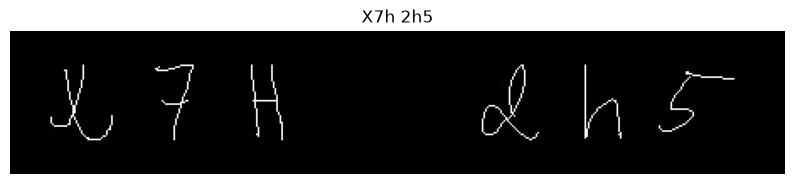

Распознанный текст: 'X7h 2h5'
Схожесть: 100.0%


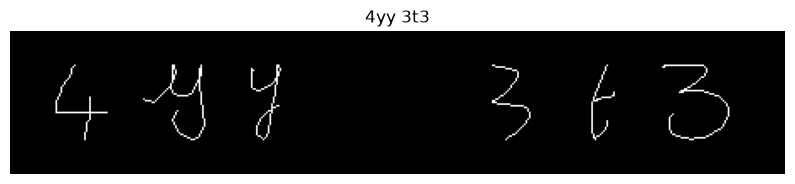

Распознанный текст: '4yy 3t3'
Схожесть: 100.0%


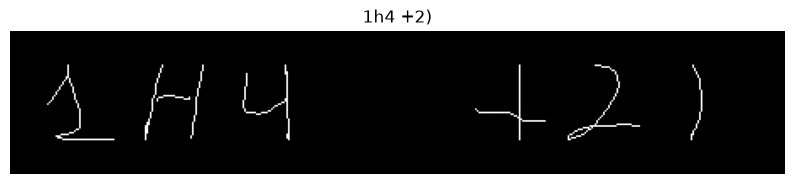

Распознанный текст: '1h4 +2)'
Схожесть: 100.0%


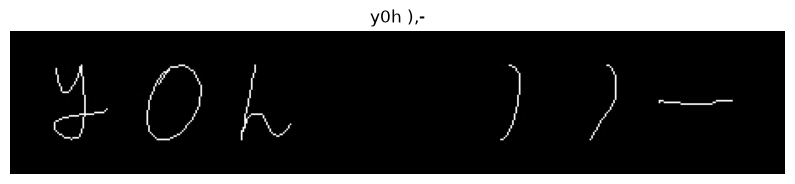

Распознанный текст: 'y0h ),-'
Схожесть: 100.0%


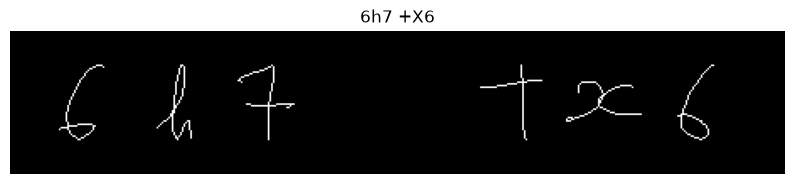

Распознанный текст: '6h7 +X6'
Схожесть: 100.0%


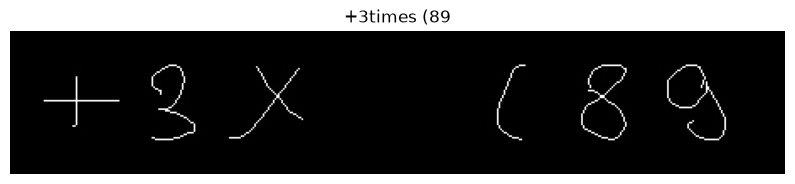

Распознанный текст: '+3times (89'
Схожесть: 100.0%


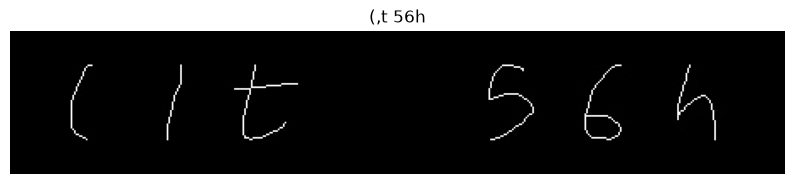

Распознанный текст: '(,t 56h'
Схожесть: 100.0%


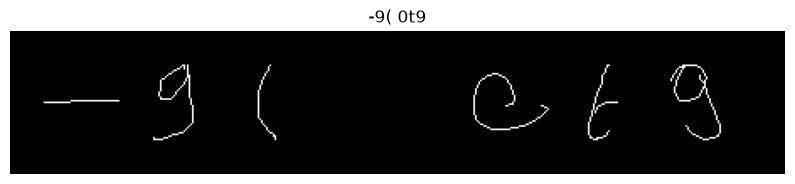

Распознанный текст: '-)( 0t9'
Схожесть: 85.7%


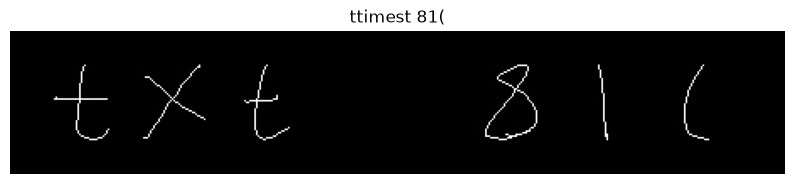

Распознанный текст: 'ttimest 81('
Схожесть: 100.0%


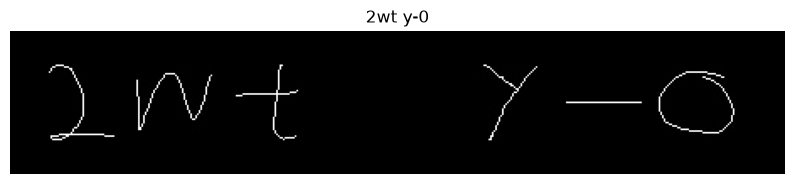

Распознанный текст: '2wt y-0'
Схожесть: 100.0%

Средняя схожесть: 98.6%


In [55]:
from difflib import SequenceMatcher

sum_sim = 0
n = 10
for i in range(n):
    true_text, generated_img = generate_sequence_image(samples_by_class, name_folders, num_words=2, word_len=3)

    plt.figure(figsize=(10, 3))
    plt.imshow(generated_img)
    plt.title(true_text)
    plt.axis('off')
    plt.show()

    recognized_text = recognize_sequence(generated_img, best_knn, name_folders)
    similarity = SequenceMatcher(None, true_text, recognized_text).ratio()
    sum_sim += similarity
    print(f"Распознанный текст: '{recognized_text}'")
    print(f"Схожесть: {similarity * 100:.1f}%")

print(f"\nСредняя схожесть: {sum_sim*100/n:.1f}%")